# Delineating the Seyon catchment with WhiteboxTools

In this lab, you will delineate the catchment upstream of the **Seyon at Valangin** hydrometric station from a digital elevation model (DEM) and an outlet coordinate.

The objective is not only to obtain a final polygon. You will inspect, map, and evaluate every intermediate product:

1. raw DEM;
2. depression-filled DEM;
3. D8 flow-direction raster;
4. flow accumulation and contributing area;
5. extracted stream network;
6. raw and snapped outlet positions;
7. watershed raster and vector boundary.

At the end, you will compare the modeled topographic catchment with independent station metadata and discuss sources of uncertainty.

## 0. Set up the environment

The repository contains the input DEM, so no data download is required. Run the next cell before any other code cell: it locates the repository root and installs `requirements.txt` into the active notebook kernel. On EPFL Noto, the first installation can take a few minutes; later runs reuse the installed packages.

All generated rasters and vectors are written to `outputs/`. By default, that folder is reset each time the setup cells are run so that every result comes from the current parameter choices.

In [29]:
from pathlib import Path
import importlib.util
import subprocess
import sys


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'requirements.txt').exists() and (candidate / 'data').exists():
            return candidate
    raise FileNotFoundError('Could not find the repository root. Clone the full repository before running the notebook.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
REQUIREMENTS = PROJECT_ROOT / 'requirements.txt'

try:
    from IPython import get_ipython
    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None:
    # %pip installs into the Python environment used by the active Jupyter kernel.
    ipython.run_line_magic('pip', f'install -r \"{REQUIREMENTS}\"')
else:
    required_modules = ['whitebox', 'geopandas', 'matplotlib', 'numpy', 'pandas', 'pyproj', 'rasterio', 'shapely']
    missing_modules = [name for name in required_modules if importlib.util.find_spec(name) is None]
    if missing_modules:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(REQUIREMENTS)])

print('Project root:', PROJECT_ROOT)

/home/tleona/code/leona/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
Project root: /home/tleona/code/leona/catchment-delineation


In [30]:
import shutil

import geopandas as gpd
try:
    from IPython.display import display
except ImportError:
    display = print
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap, LogNorm
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import rasterio
from shapely.geometry import Point
import whitebox

DEM_PATH = (PROJECT_ROOT / 'data' / 'seyon_valangin_dem_eudem25.tif').resolve()
OUTPUT_DIR = (PROJECT_ROOT / 'outputs').resolve()

RESET_OUTPUTS = True
if RESET_OUTPUTS and OUTPUT_DIR.exists():
    if OUTPUT_DIR.parent != PROJECT_ROOT:
        raise RuntimeError('Refusing to reset an output directory outside the repository.')
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILLED_DEM = OUTPUT_DIR / '01_dem_filled.tif'
D8_POINTER = OUTPUT_DIR / '02_d8_pointer.tif'
FLOW_ACCUM = OUTPUT_DIR / '03_flow_accumulation_cells.tif'
STREAMS = OUTPUT_DIR / '04_streams.tif'
OUTLET_RAW = OUTPUT_DIR / '05_outlet_raw.shp'
OUTLET_SNAPPED = OUTPUT_DIR / '06_outlet_snapped.shp'
WATERSHED_RASTER = OUTPUT_DIR / '07_watershed.tif'
WATERSHED_VECTOR = OUTPUT_DIR / '08_watershed.shp'
WATERSHED_GPKG = OUTPUT_DIR / 'seyon_watershed.gpkg'

wbt = whitebox.WhiteboxTools()
wbt.verbose = False

print(wbt.version().splitlines()[0])
print('Input DEM:', DEM_PATH)
print('Output directory:', OUTPUT_DIR)

WhiteboxTools v2.4.0 (c) Dr. John Lindsay 2017-2023
Input DEM: /home/tleona/code/leona/catchment-delineation/data/seyon_valangin_dem_eudem25.tif
Output directory: /home/tleona/code/leona/catchment-delineation/outputs


## Study site and coordinate reference systems

The official FOEN coordinates for station **2458, Seyon - Valangin** are `2,559,353 / 1,206,856` in the Swiss LV95 system (`EPSG:2056`). The DEM uses the European LAEA system (`EPSG:3035`).

GIS layers must share a coordinate reference system before distances, areas, or cell locations are compared. The following cell creates the measured outlet in LV95 and reprojects it to the DEM CRS.

Reference metadata: [FOEN Seyon - Valangin station page](https://www.hydrodaten.admin.ch/en/seen-und-fluesse/stations/2458).

In [31]:
src = rasterio.open(DEM_PATH)
array = src.read(1) # src stands for source. is just a variable/placeholder for a raster dataset
array.shape

(941, 1053)

In [32]:
from rasterio.plot import plotting_extent
extent = plotting_extent(src) # (left, bottom,right,top)

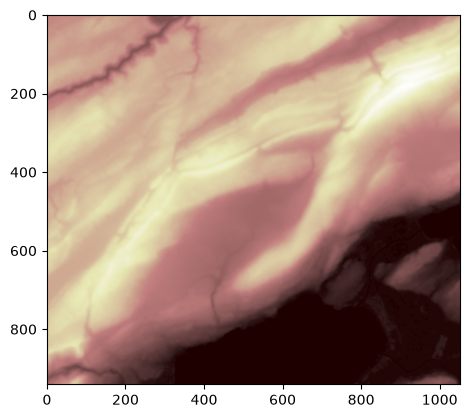

In [33]:
plt.imshow(array, cmap = 'pink')

In [34]:
array = src.read()
array.shape

(1, 941, 1053)

In [35]:
for i, dtype, nodataval in zip(src.indexes, src.dtypes, src.nodatavals):
    print(i, dtype, nodataval)

1 float32 None


In [36]:
STATION_ID = 2458
OUTLET_X_LV95 = 2_559_353
OUTLET_Y_LV95 = 1_206_856
OFFICIAL_AREA_KM2 = 112.0

with rasterio.open(DEM_PATH) as src:
    dem_crs = src.crs # retrieves the coordinate system of the raster dataset

outlet_lv95 = gpd.GeoDataFrame(
    {'station_id': [STATION_ID], 'source': ['FOEN']},
    geometry=[Point(OUTLET_X_LV95, OUTLET_Y_LV95)],
    crs='EPSG:2056',
)
outlet_dem_crs = outlet_lv95.to_crs(dem_crs)
outlet_dem_crs.to_file(OUTLET_RAW)

coordinate_table = pd.DataFrame({
    'CRS': ['LV95 (EPSG:2056)', str(dem_crs)],
    'x': [OUTLET_X_LV95, outlet_dem_crs.geometry.x.iloc[0]],
    'y': [OUTLET_Y_LV95, outlet_dem_crs.geometry.y.iloc[0]],
})
coordinate_table.round(2)

,CRS,x,y
0,LV95 (EPSG:2056),2559353.00,1206856.00
1,EPSG:3035,4085464.78,2660248.45


## 1. Inspect the raw DEM

A DEM stores one elevation value per raster cell. Before hydrological analysis, inspect its CRS, resolution, extent, missing values, and elevation range.

The supplied raster has a 25 m cell size. Each cell therefore represents $25 \times 25 = 625$ m2. This conversion will later allow us to express flow accumulation as contributing area rather than only as a cell count.

In [37]:
src.res # pixel_width and pixel_height

(25.0, 25.0)

,value
CRS,EPSG:3035
rows,941
columns,1053
cell width (m),25.0
cell height (m),25.0
minimum elevation (m),424.166412
maximum elevation (m),1595.359619


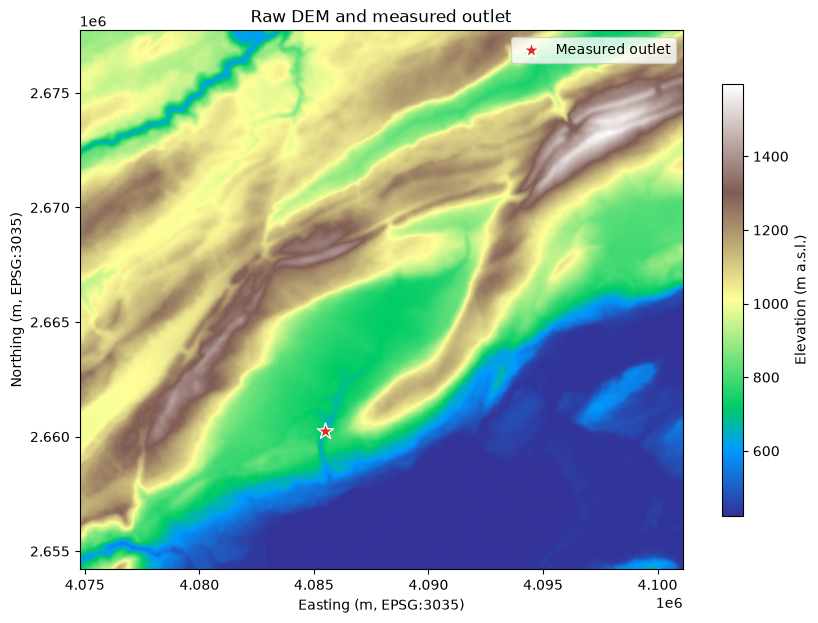

In [38]:
def read_raster(path: Path):
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
        extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
        profile = src.profile.copy() # metadata of the raster (needed to do identical rasters) (driver, dtype,nodata,widht,height,count,crs,transform)
        bounds = src.bounds
    return data, extent, profile, bounds


dem, dem_extent, dem_profile, dem_bounds = read_raster(DEM_PATH)
#cell_width = abs(dem_profile['transform'].a) # pixel width (change in x per column)
#cell_height = abs(dem_profile['transform'].e) # pixel height (change in y per row)
cell_width, cell_height = src.res
cell_area_m2 = cell_width * cell_height

metadata = pd.Series({
    'CRS': str(dem_profile['crs']),
    'rows': dem_profile['height'],
    'columns': dem_profile['width'],
    'cell width (m)': cell_width,
    'cell height (m)': cell_height,
    'minimum elevation (m)': float(dem.min()),
    'maximum elevation (m)': float(dem.max()),
})
display(metadata.to_frame('value'))

fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(dem, extent=dem_extent, origin='upper', cmap='terrain')
outlet_dem_crs.plot(ax=ax, color='#d73027', edgecolor='white', marker='*', markersize=150, label='Measured outlet')
ax.set(title='Raw DEM and measured outlet', xlabel='Easting (m, EPSG:3035)', ylabel='Northing (m, EPSG:3035)')
ax.legend(loc='upper right')
fig.colorbar(image, ax=ax, label='Elevation (m a.s.l.)', shrink=0.8)
plt.show()

### Checkpoint 1

Before continuing, answer the following:

- Is the outlet located inside the DEM?
- Which parts of the DEM appear likely to drain towards Valangin?
- Why would a geographic CRS in degrees be inconvenient for the 250 m snapping distance used later?
- Does the raster extent leave enough space around the likely upstream divide?

## 2. Fill depressions

A raw DEM often contains local pits caused by measurement noise, interpolation, roads, buildings, or real closed depressions. In a D8 routing model, an unintended pit traps all upstream flow.

`FillDepressions` raises each enclosed depression to its spill elevation and creates a continuous downslope path to the raster edge. This is a modeling decision: not every real depression should necessarily be removed. We therefore inspect the difference between the raw and filled surfaces rather than treating conditioning as a black box.

,value
changed cells,160768.0000
changed area (km2),100.4800
maximum fill depth (m),71.8526
median positive fill depth (m),4.5113


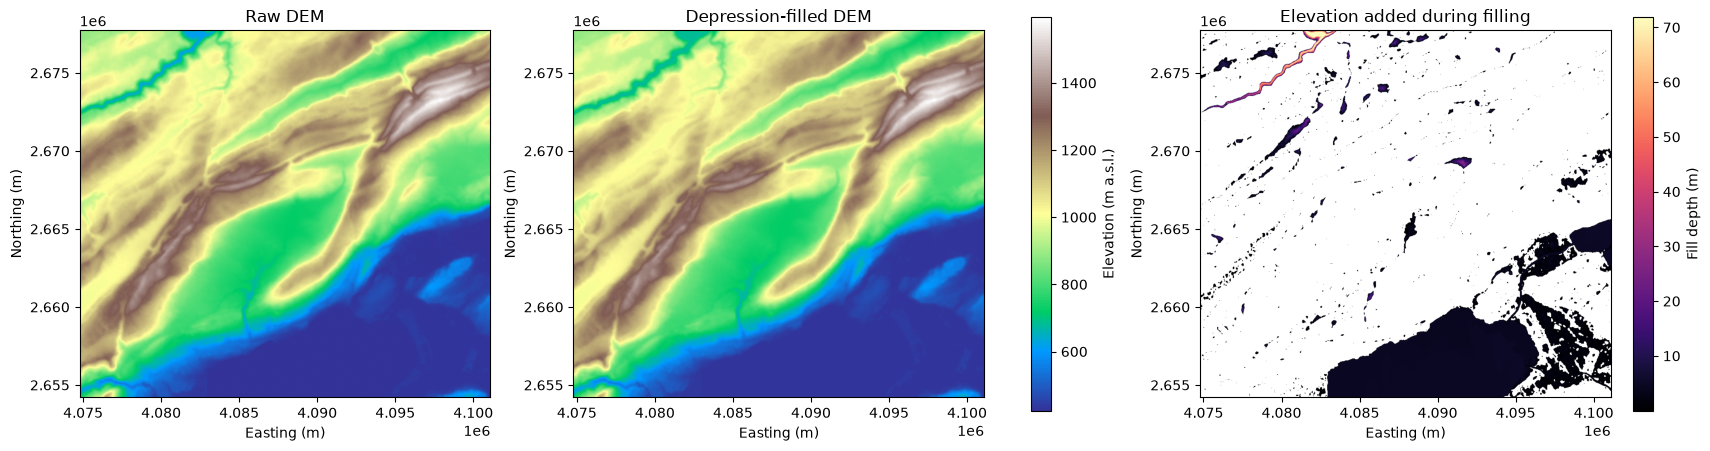

In [39]:
status = wbt.fill_depressions(str(DEM_PATH), str(FILLED_DEM), fix_flats=True)
if not FILLED_DEM.exists():
    raise RuntimeError(f'WhiteboxTools did not create {FILLED_DEM}. Status: {status}')

filled_dem, _, _, _ = read_raster(FILLED_DEM)
fill_depth = np.ma.array(filled_dem - dem, mask=np.ma.getmaskarray(dem) | np.ma.getmaskarray(filled_dem))
changed = fill_depth > 1e-6
changed_values = fill_depth[changed].compressed()

fill_summary = pd.Series({
    'changed cells': int(changed.sum()),
    'changed area (km2)': float(changed.sum() * cell_area_m2 / 1e6),
    'maximum fill depth (m)': float(changed_values.max()) if changed_values.size else 0.0,
    'median positive fill depth (m)': float(np.median(changed_values)) if changed_values.size else 0.0,
})
display(fill_summary.to_frame('value').round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
raw_image = axes[0].imshow(dem, extent=dem_extent, origin='upper', cmap='terrain')
axes[0].set_title('Raw DEM')
filled_image = axes[1].imshow(filled_dem, extent=dem_extent, origin='upper', cmap='terrain', vmin=dem.min(), vmax=dem.max())
axes[1].set_title('Depression-filled DEM')
diff_display = np.ma.masked_where(fill_depth <= 1e-6, fill_depth)
difference_image = axes[2].imshow(diff_display, extent=dem_extent, origin='upper', cmap='magma')
axes[2].set_title('Elevation added during filling')
for axis in axes:
    axis.set_xlabel('Easting (m)')
    axis.set_ylabel('Northing (m)')
fig.colorbar(raw_image, ax=axes[:2], label='Elevation (m a.s.l.)', shrink=0.8)
if changed_values.size:
    fig.colorbar(difference_image, ax=axes[2], label='Fill depth (m)', shrink=0.8)
plt.show()

### Checkpoint 2

- Are the filled cells isolated or spatially connected?
- Are most corrections small relative to the DEM vertical accuracy?
- Could any large correction represent a real lake, quarry, or closed depression?
- How might the resulting catchment change if depressions were breached instead of filled?

## 3. Calculate D8 flow direction

The D8 algorithm routes each cell to the single neighbouring cell with the steepest downslope gradient. WhiteboxTools stores direction as powers of two:

| value | 1 | 2 | 4 | 8 | 16 | 32 | 64 | 128 |
|---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| direction | NE | E | SE | S | SW | W | NW | N |

D8 is simple and efficient, but it cannot represent flow divergence because every cell has only one receiver.

,code,direction,cell count
0,1,NE,44662
1,2,E,115186
2,4,SE,234228
3,8,S,170873
4,16,SW,43782
5,32,W,96646
6,64,NW,152369
7,128,N,133048


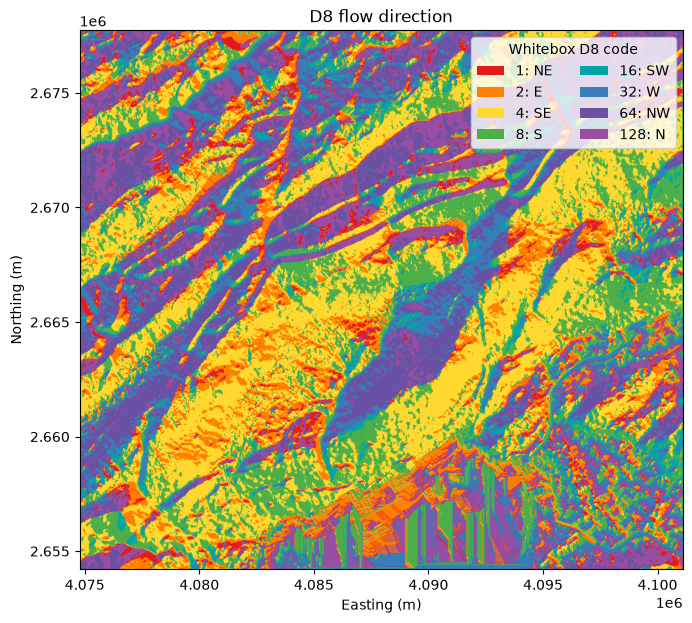

In [40]:
status = wbt.d8_pointer(str(FILLED_DEM), str(D8_POINTER))
if not D8_POINTER.exists():
    raise RuntimeError(f'WhiteboxTools did not create {D8_POINTER}. Status: {status}')

pointer, _, _, _ = read_raster(D8_POINTER)
direction_codes = [1, 2, 4, 8, 16, 32, 64, 128]
direction_names = ['NE', 'E', 'SE', 'S', 'SW', 'W', 'NW', 'N']
direction_colors = ['#e41a1c', '#ff7f00', '#ffd92f', '#4daf4a', '#00a6a6', '#377eb8', '#6a51a3', '#984ea3']
direction_counts = pd.DataFrame({
    'code': direction_codes,
    'direction': direction_names,
    'cell count': [int(np.sum(pointer == code)) for code in direction_codes],
})
display(direction_counts)

pointer_display = np.ma.masked_where(~np.isin(pointer, direction_codes), pointer)
boundaries = [0.5, 1.5, 3, 6, 12, 24, 48, 96, 160]
cmap = ListedColormap(direction_colors)
norm = BoundaryNorm(boundaries, cmap.N)

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(pointer_display, extent=dem_extent, origin='upper', cmap=cmap, norm=norm)
ax.set(title='D8 flow direction', xlabel='Easting (m)', ylabel='Northing (m)')
legend_handles = [Patch(facecolor=color, label=f'{code}: {name}') for code, name, color in zip(direction_codes, direction_names, direction_colors)]
ax.legend(handles=legend_handles, title='Whitebox D8 code', ncol=2, loc='upper right')
plt.show()

### Checkpoint 3

- Why is the flow-direction map visually noisy even when the regional drainage pattern is coherent?
- What directional bias might a square D8 grid introduce?
- Which alternative routing methods allow water to be divided among several downslope cells?

## 4. Calculate flow accumulation

Flow accumulation counts the number of upstream cells routed through each cell. Valley bottoms receive flow from many cells, while ridges receive flow from few cells. Because values span several orders of magnitude, a logarithmic color scale is appropriate.

Contributing area is calculated as:

$$A = N_{cells} \times A_{cell}$$

Maximum accumulation: 534,785 cells
Maximum contributing area: 334.2 km2


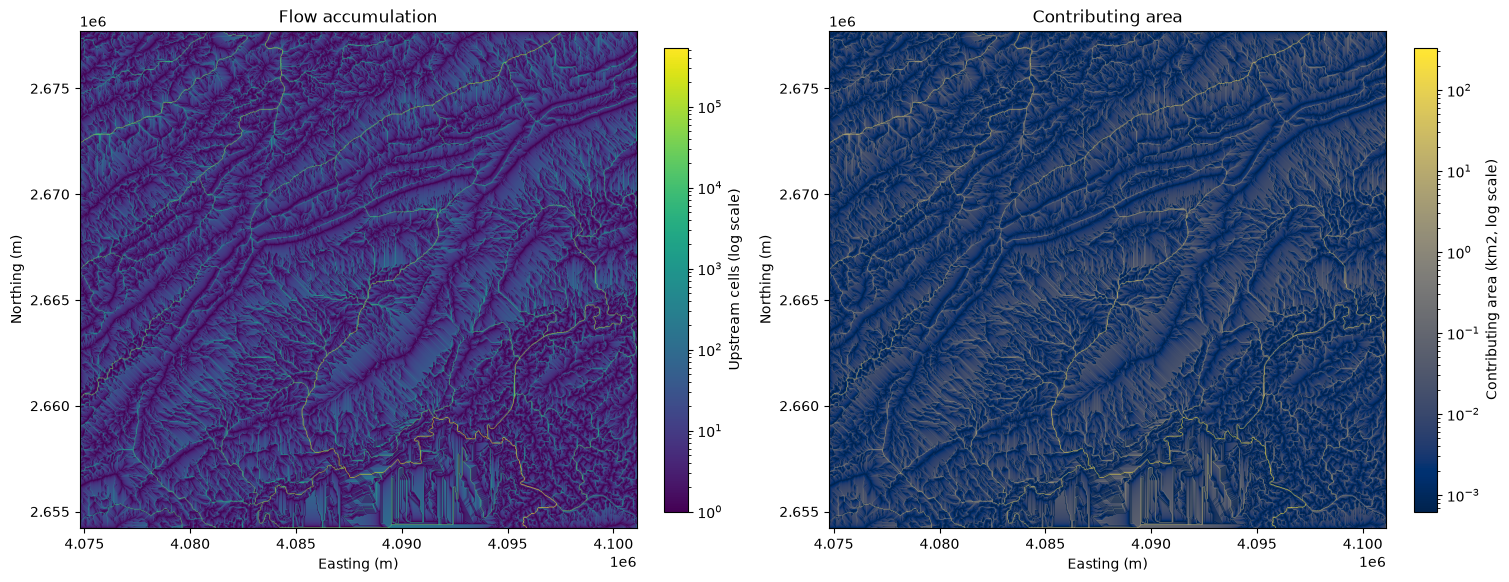

In [41]:
status = wbt.d8_flow_accumulation(
    str(FILLED_DEM),
    str(FLOW_ACCUM),
    out_type='cells',
    log=False,
)
if not FLOW_ACCUM.exists():
    raise RuntimeError(f'WhiteboxTools did not create {FLOW_ACCUM}. Status: {status}')

accumulation, _, _, _ = read_raster(FLOW_ACCUM)
accumulation_positive = np.ma.masked_less_equal(accumulation, 0)
contributing_area_km2 = accumulation * cell_area_m2 / 1e6

print(f'Maximum accumulation: {float(accumulation.max()):,.0f} cells')
print(f'Maximum contributing area: {float(contributing_area_km2.max()):,.1f} km2')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
axes[0].imshow(filled_dem, extent=dem_extent, origin='upper', cmap='Greys_r')
acc_image = axes[0].imshow(
    accumulation_positive,
    extent=dem_extent,
    origin='upper',
    cmap='viridis',
    norm=LogNorm(vmin=1, vmax=float(accumulation_positive.max())),
)
axes[0].set_title('Flow accumulation')
fig.colorbar(acc_image, ax=axes[0], label='Upstream cells (log scale)', shrink=0.8)

area_image = axes[1].imshow(
    np.ma.masked_less_equal(contributing_area_km2, 0),
    extent=dem_extent,
    origin='upper',
    cmap='cividis',
    norm=LogNorm(vmin=cell_area_m2 / 1e6, vmax=float(contributing_area_km2.max())),
)
axes[1].set_title('Contributing area')
fig.colorbar(area_image, ax=axes[1], label='Contributing area (km2, log scale)', shrink=0.8)
for axis in axes:
    axis.set_xlabel('Easting (m)')
    axis.set_ylabel('Northing (m)')
plt.show()

## 5. Extract a modeled stream network

A DEM does not contain a unique stream network. We define a channel wherever contributing area exceeds a threshold. Here the default threshold is **1 km2**. A smaller threshold produces a denser network; a larger threshold retains only major channels.

The threshold is first converted from square kilometres to cells so that it is independent of raster resolution in the written workflow.

Threshold: 1,600 cells = 1.00 km2
Stream cells: 15,733
Approximate raster stream length in the DEM extent: 393.3 km


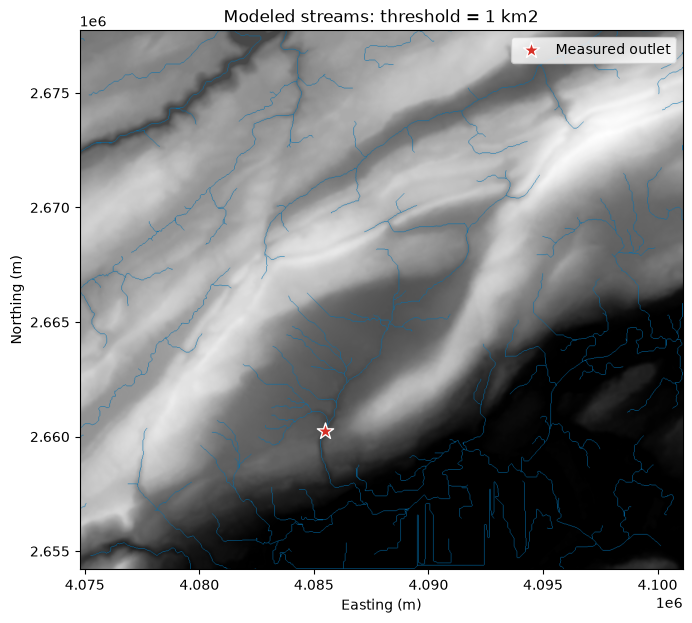

In [42]:
STREAM_THRESHOLD_KM2 = 1.0
stream_threshold_cells = STREAM_THRESHOLD_KM2 * 1e6 / cell_area_m2

status = wbt.extract_streams(
    str(FLOW_ACCUM),
    str(STREAMS),
    threshold=stream_threshold_cells,
    zero_background=True,
)
if not STREAMS.exists():
    raise RuntimeError(f'WhiteboxTools did not create {STREAMS}. Status: {status}')

streams, _, _, _ = read_raster(STREAMS)
stream_mask = np.ma.masked_where(streams <= 0, streams)
stream_cell_count = int(np.sum(streams > 0))
approximate_stream_length_km = stream_cell_count * cell_width / 1000

print(f'Threshold: {stream_threshold_cells:,.0f} cells = {STREAM_THRESHOLD_KM2:.2f} km2')
print(f'Stream cells: {stream_cell_count:,}')
print(f'Approximate raster stream length in the DEM extent: {approximate_stream_length_km:.1f} km')

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(filled_dem, extent=dem_extent, origin='upper', cmap='Greys_r')
ax.imshow(stream_mask, extent=dem_extent, origin='upper', cmap=ListedColormap(['#0072b2']), alpha=0.9)
outlet_dem_crs.plot(ax=ax, color='#d73027', edgecolor='white', marker='*', markersize=150, label='Measured outlet')
ax.set(title=f'Modeled streams: threshold = {STREAM_THRESHOLD_KM2:g} km2', xlabel='Easting (m)', ylabel='Northing (m)')
ax.legend()
plt.show()

### Checkpoint 4

Change `STREAM_THRESHOLD_KM2` to `0.5`, `2`, and `5`, then rerun the preceding cell. Record how stream length and network density change.

- Is there a single objectively correct threshold?
- Which independent data could be used to calibrate it?
- Why is approximate raster stream length sensitive to diagonal flow paths?

## 6. Snap the measured outlet to a drainage path

A measured station coordinate rarely lies exactly on the highest-accumulation DEM cell. Positional uncertainty, raster resolution, and imperfect terrain representation can place it on a hillslope cell. Delineating from that cell would produce an unrealistically small catchment.

`SnapPourPoints` searches within a specified radius and moves the outlet to the cell with the greatest flow accumulation. We use 250 m, matching the processing workflow from which this teaching example was derived. The displacement must always be checked.

,point,x,y
0,measured,4085464.78,2660248.45
1,snapped,4085462.50,2660112.50


Snap displacement: 136.0 m


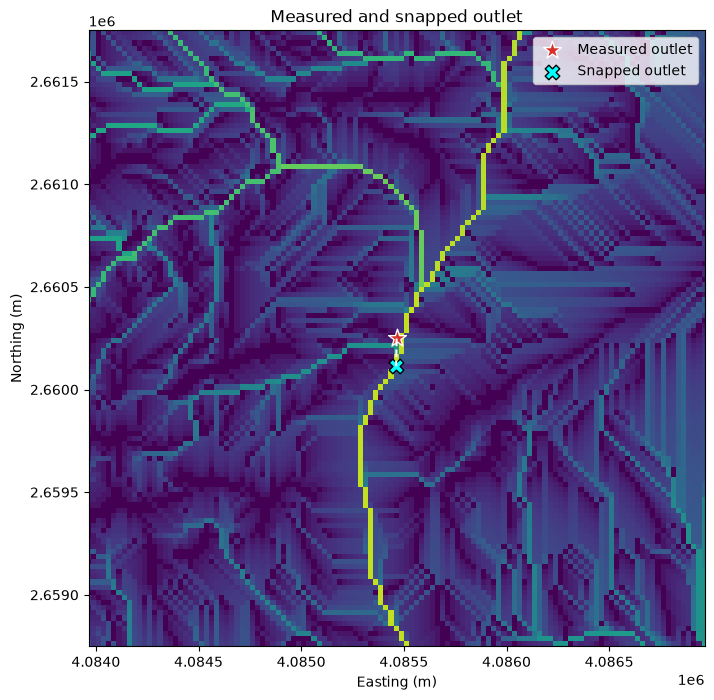

In [43]:
SNAP_DISTANCE_M = 250.0
status = wbt.snap_pour_points(
    str(OUTLET_RAW),
    str(FLOW_ACCUM),
    str(OUTLET_SNAPPED),
    snap_dist=SNAP_DISTANCE_M,
)
if not OUTLET_SNAPPED.exists():
    raise RuntimeError(f'WhiteboxTools did not create {OUTLET_SNAPPED}. Status: {status}')

outlet_snapped = gpd.read_file(OUTLET_SNAPPED)
snap_displacement_m = outlet_dem_crs.geometry.iloc[0].distance(outlet_snapped.geometry.iloc[0])

snap_table = pd.DataFrame({
    'point': ['measured', 'snapped'],
    'x': [outlet_dem_crs.geometry.x.iloc[0], outlet_snapped.geometry.x.iloc[0]],
    'y': [outlet_dem_crs.geometry.y.iloc[0], outlet_snapped.geometry.y.iloc[0]],
})
display(snap_table.round(2))
print(f'Snap displacement: {snap_displacement_m:.1f} m')

x0, y0 = outlet_dem_crs.geometry.x.iloc[0], outlet_dem_crs.geometry.y.iloc[0]
zoom = 1_500
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(
    accumulation_positive,
    extent=dem_extent,
    origin='upper',
    cmap='viridis',
    norm=LogNorm(vmin=1, vmax=float(accumulation_positive.max())),
)
outlet_dem_crs.plot(ax=ax, color='#d73027', edgecolor='white', marker='*', markersize=180, label='Measured outlet')
outlet_snapped.plot(ax=ax, color='#00ffff', edgecolor='black', marker='X', markersize=110, label='Snapped outlet')
ax.plot(
    [outlet_dem_crs.geometry.x.iloc[0], outlet_snapped.geometry.x.iloc[0]],
    [outlet_dem_crs.geometry.y.iloc[0], outlet_snapped.geometry.y.iloc[0]],
    color='white', linewidth=1.5, linestyle='--',
)
ax.set_xlim(x0 - zoom, x0 + zoom)
ax.set_ylim(y0 - zoom, y0 + zoom)
ax.set(title='Measured and snapped outlet', xlabel='Easting (m)', ylabel='Northing (m)')
ax.legend()
plt.show()

### Checkpoint 5

- Is the displacement small relative to the 250 m search radius?
- Did the point move towards a higher-accumulation cell?
- What could go wrong if the search radius crosses into a neighbouring river?
- Should snapping be accepted automatically, or should a human inspect every moved outlet?

## 7. Delineate the upstream watershed

Starting from the snapped outlet, `Watershed` follows the D8 pointer grid upstream and labels every cell whose modeled flow path reaches that outlet. The result is initially a raster because the routing operation is cell based.

Watershed cells: 160,258
Raster area: 100.16 km2


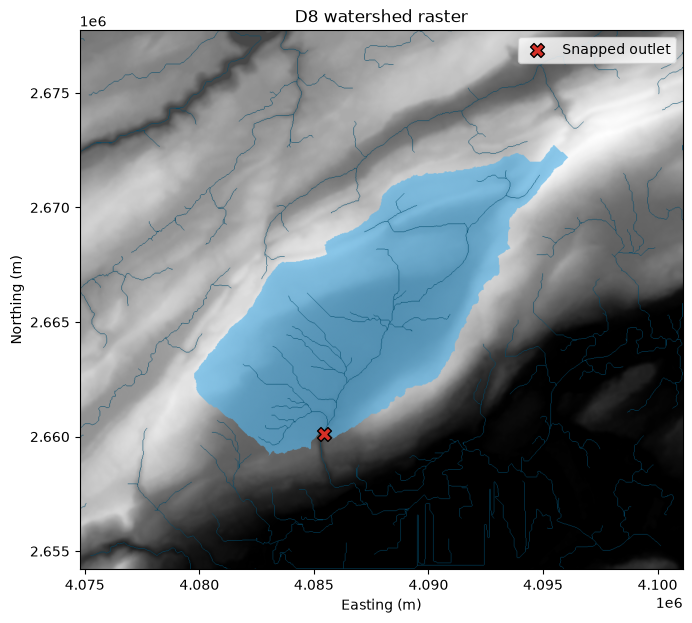

In [44]:
status = wbt.watershed(str(D8_POINTER), str(OUTLET_SNAPPED), str(WATERSHED_RASTER))
if not WATERSHED_RASTER.exists():
    raise RuntimeError(f'WhiteboxTools did not create {WATERSHED_RASTER}. Status: {status}')

watershed_raster, _, _, _ = read_raster(WATERSHED_RASTER)
watershed_mask = np.ma.masked_where(watershed_raster <= 0, watershed_raster)
watershed_cells = int(np.sum(watershed_raster > 0))
watershed_raster_area_km2 = watershed_cells * cell_area_m2 / 1e6

print(f'Watershed cells: {watershed_cells:,}')
print(f'Raster area: {watershed_raster_area_km2:.2f} km2')

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(filled_dem, extent=dem_extent, origin='upper', cmap='Greys_r')
ax.imshow(watershed_mask, extent=dem_extent, origin='upper', cmap=ListedColormap(['#56b4e9']), alpha=0.65)
ax.imshow(stream_mask, extent=dem_extent, origin='upper', cmap=ListedColormap(['#004c6d']), alpha=0.9)
outlet_snapped.plot(ax=ax, color='#d73027', edgecolor='black', marker='X', markersize=100, label='Snapped outlet')
ax.set(title='D8 watershed raster', xlabel='Easting (m)', ylabel='Northing (m)')
ax.legend()
plt.show()

## 8. Convert the watershed to a polygon and evaluate it

Vector polygons are convenient for cartography, area calculation, clipping other datasets, and spatial overlays. We convert the watershed raster to polygons and dissolve its parts into one catchment geometry.

The official FOEN station metadata report a catchment area of approximately **112 km2**. Agreement is not expected to be exact because the two boundaries may have different data sources, resolutions, and definitions.

In [45]:
status = wbt.raster_to_vector_polygons(str(WATERSHED_RASTER), str(WATERSHED_VECTOR))
if not WATERSHED_VECTOR.exists():
    raise RuntimeError(f'WhiteboxTools did not create {WATERSHED_VECTOR}. Status: {status}')

watershed_parts = gpd.read_file(WATERSHED_VECTOR)
watershed = watershed_parts.dissolve().reset_index(drop=True)
watershed['station_id'] = STATION_ID
watershed['area_km2'] = watershed.geometry.area / 1e6
watershed.to_file(WATERSHED_GPKG, layer='watershed', driver='GPKG')

modeled_area_km2 = float(watershed['area_km2'].iloc[0])
area_difference_km2 = modeled_area_km2 - OFFICIAL_AREA_KM2
relative_difference_percent = 100 * area_difference_km2 / OFFICIAL_AREA_KM2

evaluation = pd.Series({
    'modeled topographic area (km2)': modeled_area_km2,
    'FOEN reference area (km2)': OFFICIAL_AREA_KM2,
    'difference (km2)': area_difference_km2,
    'relative difference (%)': relative_difference_percent,
    'outlet displacement (m)': snap_displacement_m,
})
evaluation.to_frame('value').round(2)

,value
modeled topographic area (km2),100.16
FOEN reference area (km2),112.00
difference (km2),-11.84
relative difference (%),-10.57
outlet displacement (m),135.97


### Interpreting the area difference

A plausible map is not automatically a correct hydrological model. Consider at least the following explanations:

- the 25 m DEM smooths or displaces small ridges and channels;
- filling changes local drainage connectivity;
- D8 restricts each cell to one of eight directions;
- the snapped outlet may not represent the exact gauging cross-section;
- the official boundary may have been derived from a different terrain model;
- a hydrological catchment can differ from a surface topographic catchment because of subsurface transfers, artificial drainage, or water-management infrastructure.

The difference should therefore trigger investigation, not silent adjustment of the result.

## 9. Final map

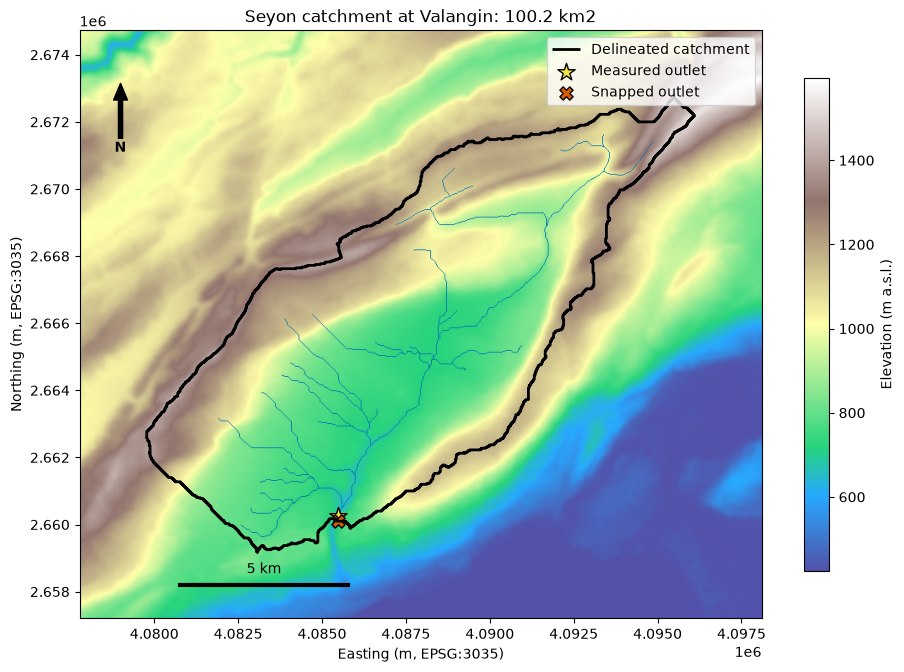

In [46]:
stream_in_watershed = np.ma.masked_where((streams <= 0) | (watershed_raster <= 0), streams)

fig, ax = plt.subplots(figsize=(11, 8))
dem_image = ax.imshow(dem, extent=dem_extent, origin='upper', cmap='terrain', alpha=0.85)
ax.imshow(stream_in_watershed, extent=dem_extent, origin='upper', cmap=ListedColormap(['#0072b2']), alpha=0.9)
watershed.boundary.plot(ax=ax, color='black', linewidth=2.0, label='Delineated catchment')
outlet_dem_crs.plot(ax=ax, color='#f0e442', edgecolor='black', marker='*', markersize=170, label='Measured outlet')
outlet_snapped.plot(ax=ax, color='#d55e00', edgecolor='black', marker='X', markersize=90, label='Snapped outlet')

minx, miny, maxx, maxy = watershed.total_bounds
pad = 2_000
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)

scale_length = 5_000
scale_x = minx + 1_000
scale_y = miny - 1_000
ax.plot([scale_x, scale_x + scale_length], [scale_y, scale_y], color='black', linewidth=3)
ax.text(scale_x + scale_length / 2, scale_y + 250, '5 km', ha='center', va='bottom')
ax.annotate('N', xy=(0.06, 0.91), xytext=(0.06, 0.80), xycoords='axes fraction',
            ha='center', va='center', fontweight='bold',
            arrowprops=dict(facecolor='black', width=3, headwidth=10))

ax.set(
    title=f'Seyon catchment at Valangin: {modeled_area_km2:.1f} km2',
    xlabel='Easting (m, EPSG:3035)',
    ylabel='Northing (m, EPSG:3035)',
)
ax.legend(loc='upper right')
fig.colorbar(dem_image, ax=ax, label='Elevation (m a.s.l.)', shrink=0.8)
fig.savefig(OUTPUT_DIR / 'final_catchment_map.png', dpi=200, bbox_inches='tight')
plt.show()

## Sensitivity experiments

Complete at least two of the following experiments and explain the result.

1. **Stream threshold:** repeat the stream extraction for `0.5`, `2`, and `5 km2`. Compare network length and visual realism.
2. **Snap distance:** repeat snapping and delineation for `50`, `100`, `250`, and `500 m`. Plot catchment area against snap distance.
3. **No DEM filling:** calculate D8 direction and accumulation from the raw DEM. Locate where flow becomes trapped or disconnected.
4. **Breaching instead of filling:** replace `FillDepressions` with a WhiteboxTools breaching method and compare the resulting drainage network and catchment area.
5. **Resolution:** resample the DEM to 50 or 100 m and quantify changes in outlet position, stream network, and catchment area.

## Submission checklist

Your short report should contain:

- one figure comparing the raw and conditioned DEM;
- one flow-accumulation map with a clearly labelled logarithmic scale;
- one map showing measured and snapped outlet positions;
- the final catchment map and calculated area;
- comparison with the `112 km2` reference area;
- a concise explanation of the principal uncertainty sources; and
- results from at least two sensitivity experiments.

In [47]:
print('Generated files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f'  {path.name:35s} {path.stat().st_size / 1e6:7.2f} MB')

Generated files:
  01_dem_filled.tif                      7.93 MB
  02_d8_pointer.tif                      1.99 MB
  03_flow_accumulation_cells.tif         3.97 MB
  04_streams.tif                         3.97 MB
  05_outlet_raw.cpg                      0.00 MB
  05_outlet_raw.dbf                      0.00 MB
  05_outlet_raw.prj                      0.00 MB
  05_outlet_raw.shp                      0.00 MB
  05_outlet_raw.shx                      0.00 MB
  06_outlet_snapped.dbf                  0.00 MB
  06_outlet_snapped.prj                  0.00 MB
  06_outlet_snapped.shp                  0.00 MB
  06_outlet_snapped.shx                  0.00 MB
  07_watershed.tif                       3.97 MB
  08_watershed.dbf                       0.00 MB
  08_watershed.prj                       0.00 MB
  08_watershed.shp                       0.03 MB
  08_watershed.shx                       0.00 MB
  final_catchment_map.png                1.16 MB
  seyon_watershed.gpkg                   0.12 MB
